In [43]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [44]:
# --------------------------------------------------
# STEP 1: LOAD THE DATASET
# --------------------------------------------------

# 1B: Fashion MNIST Dataset
train_data = pd.read_csv('cifar-10.csv')



In [45]:
# Separate features and labels
x = train_data.drop('label', axis=1).values
y = train_data['label'].values
# Convert labels into consecutive values (0 to 23)
encoder = LabelEncoder()
y = encoder.fit_transform(y)


# Split training data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


In [46]:
# --------------------------------------------------
# STEP 2: PREPROCESS THE DATA
# --------------------------------------------------

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') /255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images into 1D vectors
x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

In [47]:
# --------------------------------------------------
# STEP 3: DEFINE THE FNN MODEL
# --------------------------------------------------

model = keras.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [48]:
# --------------------------------------------------
# STEP 4: COMPILE THE MODEL
# --------------------------------------------------

model.compile(
    optimizer=keras.optimizers.SGD(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [49]:
# --------------------------------------------------
# STEP 5: TRAIN THE MODEL
# --------------------------------------------------

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.3023 - loss: 1.9313 - val_accuracy: 0.3670 - val_loss: 1.7927
Epoch 2/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.3747 - loss: 1.7533 - val_accuracy: 0.3762 - val_loss: 1.7444
Epoch 3/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.4041 - loss: 1.6776 - val_accuracy: 0.4180 - val_loss: 1.6588
Epoch 4/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4218 - loss: 1.6235 - val_accuracy: 0.4347 - val_loss: 1.6105
Epoch 5/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.4357 - loss: 1.5869 - val_accuracy: 0.4347 - val_loss: 1.5961
Epoch 6/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.4479 - loss: 1.5515 - val_accuracy: 0.4487 - val_loss: 1.5574
Epoch 7/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4606 - loss: 1.5220 - val_accuracy: 0.4695 - val_loss: 1.5158
Epoch 8/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4658 - lo

In [50]:
# --------------------------------------------------
# STEP 6: EVALUATE THE MODEL
# --------------------------------------------------

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.4757 - loss: 1.4961
Test Loss: 1.4960790872573853
Test Accuracy: 47.56999909877777 %


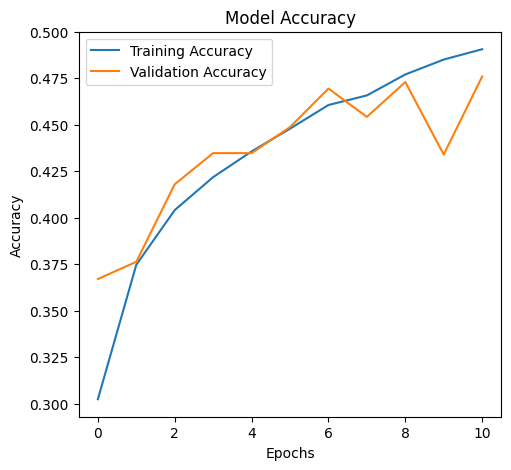

In [51]:
# --------------------------------------------------
# STEP 7: PLOT TRAINING LOSS AND ACCURACY
# --------------------------------------------------

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

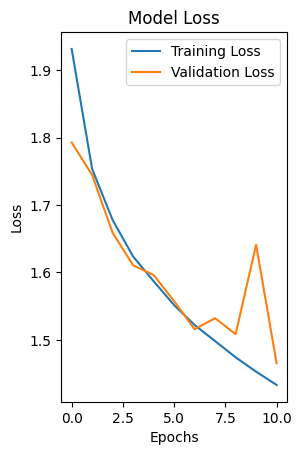

In [52]:
# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()
